# End-to-End ETL Data Warehouse Pipeline — Run Walkthrough

**Portfolio project — all data is synthetic** (generated by `src/generate_data.py`
with `random_state=42`). No real companies, customers, or transactions are involved.

This notebook walks through a full pipeline run: messy raw CSVs -> extract ->
data-quality profiling -> cleaning/transform -> load into a SQLite warehouse
with **SCD Type 2** `dim_customer`, `dim_product`, `dim_date`, and `fact_orders`
-> business questions answered from the marts with SQL.

In [1]:
import sys
from pathlib import Path
import sqlite3

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent / "src"))
REPO = Path.cwd().parent
plt.rcParams["figure.dpi"] = 150
print("pandas", pd.__version__, "| repo:", REPO)

pandas 3.0.6 | repo: /home/hatch/workspace/github/etl-data-warehouse-pipeline


## 1. Generate the messy raw data

The generator creates intentionally dirty retail data: nulls, exact duplicates,
mixed casing (`Gold` vs `GOLD`), three different date formats, invalid emails,
negative quantities, orphan foreign keys, and costs above list price. Batch 2 is
the incremental load that drives the SCD Type 2 demo.

In [2]:
from generate_data import main as generate
generate()
for p in sorted((REPO / "data" / "raw").rglob("*.csv")):
    print(f"{p.relative_to(REPO)}: {pd.read_csv(p).shape[0]:,} rows")

wrote data/raw/customers_raw.csv: 540 rows
wrote data/raw/orders_raw.csv: 2,080 rows
wrote data/raw/products_raw.csv: 63 rows
wrote data/raw/batch2/customers_batch2.csv: 62 rows
wrote data/raw/batch2/orders_batch2.csv: 520 rows
data/raw/batch2/customers_batch2.csv: 62 rows
data/raw/batch2/orders_batch2.csv: 520 rows
data/raw/customers_raw.csv: 540 rows
data/raw/orders_raw.csv: 2,080 rows
data/raw/products_raw.csv: 63 rows


## 2. Extract + profile raw data quality (BEFORE)

In [3]:
from extract import extract_batch
from data_quality import profile_raw, issue_score

raw1 = extract_batch(1)
print("--- raw customers sample ---")
display(raw1["customers"].head(3))
print("--- raw orders sample ---")
display(raw1["orders"].head(3))

dq_raw = profile_raw(raw1)
print("Raw composite issue score per entity (%):", issue_score(dq_raw))

[extract] batch 1 customers: 540 raw rows from customers_raw.csv
[extract] batch 1 orders: 2,080 raw rows from orders_raw.csv
[extract] batch 1 products: 63 raw rows from products_raw.csv
--- raw customers sample ---


,customer_id,full_name,email,phone,city,state,signup_date,loyalty_tier
0,CUST-0230,Priya Jackson,priyajackson229example.com,(214) 555-3031,Frisco,TX,21-05-2023,Bronze
1,CUST-0074,sofia patel,Sofia.Patel73@Example.Com,+1 214 555-9431,Miami,FL,2023-12-01,Silver
2,CUST-0492,owen taylor,NaN,214-555-8448,Dallas,TX,08/19/2022,Platinum


--- raw orders sample ---


,order_id,customer_id,product_id,order_date,quantity,unit_price,discount_pct,order_status
0,ORD-001365,CUST-0305,PROD-006,03/05/2025,2.0,387.86,0.8,CANCELLED
1,ORD-000423,CUST-0256,PROD-056,11/22/2024,2.0,192.09,6.6,CANCELLED
2,ORD-000539,CUST-0389,PROD-047,2025-01-14,2.0,389.5,6.7,Pending


Raw composite issue score per entity (%): {'customers': np.float64(3.72), 'orders': np.float64(1.64), 'products': np.float64(1.88)}


## 3. Transform — cleaning, conforming, validation

Every rule is explicit and counted in `notes` (see `src/transform.py`):
null/invalid handling, dedupe on natural keys, date parsing across 3 formats,
email regex validation, tier/status canonicalisation, cost imputation by
category median, margin capping, and orphan exclusion.

In [4]:
from transform import clean_customers, clean_orders, clean_products

notes = {}
stg = {
    "customers": clean_customers(raw1["customers"], notes),
    "orders": clean_orders(raw1["orders"], notes),
    "products": clean_products(raw1["products"], notes),
}
print("Cleaning report (rows affected per rule):")
for k, v in notes.items():
    print(f"  {k:38s} {v}")

print("\n--- cleaned customers sample ---")
display(stg["customers"].head(3))

Cleaning report (rows affected per rule):
  customers_raw_rows                     540
  customers_exact_dupes_dropped          40
  customers_after_dedupe                 500
  customers_invalid_emails_nulled        18
  customers_bad_dates_dropped            0
  customers_clean_rows                   500
  orders_raw_rows                        2080
  orders_exact_dupes_dropped             80
  orders_after_dedupe                    2000
  orders_bad_dates_dropped               0
  orders_bad_quantity_dropped            60
  orders_bad_price_dropped               20
  orders_discount_capped                 10
  orders_clean_rows                      1920
  products_raw_rows                      63
  products_exact_dupes_dropped           3
  products_null_cost_imputed             4
  products_invalid_margin_capped         6
  products_clean_rows                    60

--- cleaned customers sample ---


,customer_id,full_name,email,phone,city,state,signup_date,loyalty_tier
0,CUST-0326,Ethan Garcia,NaN,(214) 555-6060,Phoenix,AZ,2022-10-11,Gold
1,CUST-0447,Anya Joshi,anya.joshi446@example.com,214-555-3833,Boston,MA,2023-12-20,Bronze
2,CUST-0322,Sofia Jackson,sofia.jackson321@example.com,(214) 555-9641,Atlanta,GA,2024-09-15,Platinum


## 4. Load the warehouse — batch 1 (full) + batch 2 (incremental, SCD Type 2)

In [5]:
from run_pipeline import run
result = run()
counts = result["counts"]

[extract] batch 1 customers: 540 raw rows from customers_raw.csv
[extract] batch 1 orders: 2,080 raw rows from orders_raw.csv
[extract] batch 1 products: 63 raw rows from products_raw.csv

=========== DATA QUALITY: BEFORE vs AFTER ===========

[customers] raw rows: 540 -> clean rows: 500
  duplicate rate : 7.41% -> 0.0%
  null email         : 7.78% -> 11.6%
  null phone         : 9.63% -> 9.6%
  null city          : 4.81% -> 5.0%
  null loyalty_tier  : 4.07% -> 0.0%
  invalid_email_rate_pct  : 14.63% -> 0.0%

[orders] raw rows: 2,080 -> clean rows: 1,920
  duplicate rate : 3.85% -> 0.0%
  null quantity      : 2.02% -> 0.0%
  null unit_price    : 1.01% -> 0.0%
  null discount_pct  : 3.03% -> 0.0%
  bad_quantity_rate_pct   : 3.03% -> 0.0%
  orphan_customer_rate_pct: 3.03% -> 0.0%
  orphan_product_rate_pct : 2.02% -> 0.0%

[products] raw rows: 63 -> clean rows: 60
  duplicate rate : 4.76% -> 0.0%
  null cost          : 6.35% -> 0.0%
  invalid_margin_rate_pct : 9.52% -> 0.0%



[load] batch 1: dim_customer {'inserted': 500, 'scd2_updated': 0, 'unchanged': 0}, fact rows loaded: 1,824, orphan orders excluded: 96
[extract] batch 2 customers: 62 raw rows from customers_batch2.csv
[extract] batch 2 orders: 520 raw rows from orders_batch2.csv


[load] batch 2: dim_customer {'inserted': 30, 'scd2_updated': 30, 'unchanged': 0}, fact rows loaded: 457, orphan orders excluded: 24

=========== ROW COUNTS PER LAYER ===========
  stg_customers  : 560
  stg_orders     : 2,401
  stg_products   : 60
  dim_customer   : 560
  dim_product    : 60
  dim_date       : 637
  fact_orders    : 2,281



## 5. Row counts per layer

stg_customers     560
stg_orders       2401
stg_products       60
dim_customer      560
dim_product        60
dim_date          637
fact_orders      2281


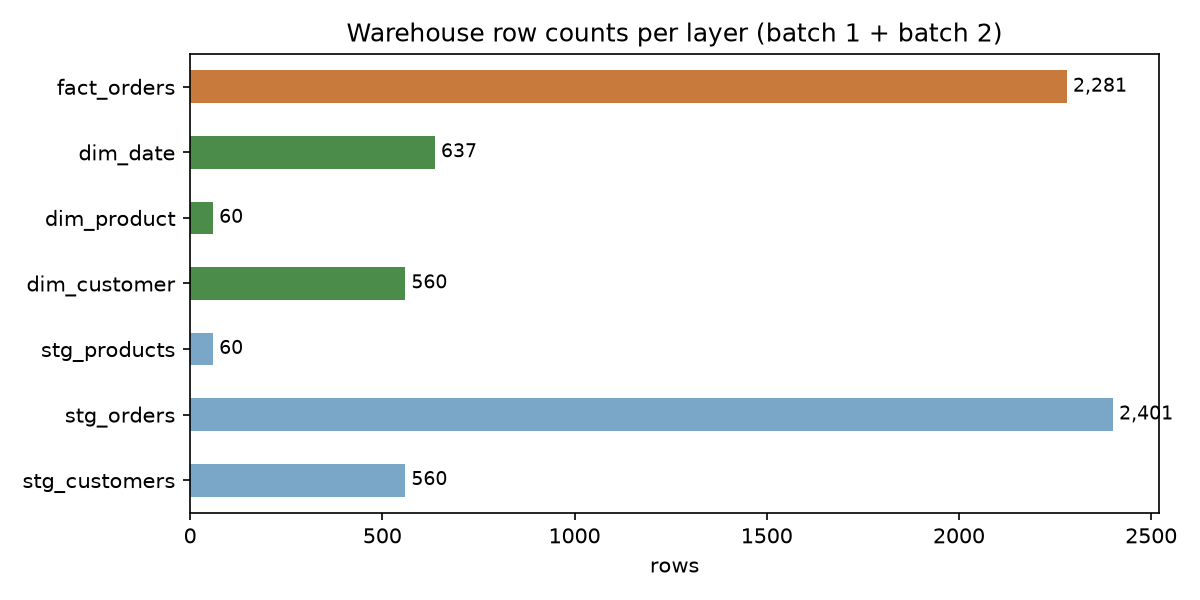

In [6]:
layers = pd.Series(counts)
print(layers.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#7aa7c7"] * 3 + ["#4c8c4a"] * 3 + ["#c77a3b"]
layers.plot.barh(ax=ax, color=colors)
ax.set_xlabel("rows")
ax.set_title("Warehouse row counts per layer (batch 1 + batch 2)")
for i, v in enumerate(layers.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(REPO / "images" / "row_counts.png", dpi=150)
display(Image(str(REPO / "images" / "row_counts.png")))

## 6. SCD Type 2 in action — customer history is preserved

Batch 2 changed city / loyalty tier for 30 customers. Old rows are closed out
(`is_current = 0`, `end_date` = day before the new load) and new rows carry new
surrogate keys — point-in-time reporting stays correct.

In [7]:
conn = sqlite3.connect(REPO / "warehouse.db")
scd = pd.read_sql(
    "SELECT customer_id, city, loyalty_tier, effective_date, end_date, is_current "
    "FROM dim_customer "
    "WHERE customer_id IN (SELECT customer_id FROM dim_customer "
    "GROUP BY customer_id HAVING COUNT(*) > 1) "
    "ORDER BY customer_id, effective_date LIMIT 6", conn)
display(scd)
print("customers with 2 versions:",
      pd.read_sql("SELECT COUNT(*) n FROM (SELECT customer_id FROM dim_customer "
                  "GROUP BY customer_id HAVING COUNT(*)=2)", conn)["n"][0])

,customer_id,city,loyalty_tier,effective_date,end_date,is_current
0,CUST-0026,Austin,Gold,2025-07-01,2025-09-30,0
1,CUST-0026,Austin,Silver,2025-10-01,9999-12-31,1
2,CUST-0066,Houston,Platinum,2025-07-01,2025-09-30,0
3,CUST-0066,Dallas,Gold,2025-10-01,9999-12-31,1
4,CUST-0071,Plano,Platinum,2025-07-01,2025-09-30,0
5,CUST-0071,Austin,Bronze,2025-10-01,9999-12-31,1


customers with 2 versions: 30


## 7. Data quality — BEFORE vs AFTER

Composite issue score = mean of duplicate rate, per-column null rates
(excluding id columns) and the domain-rule violation rates. Cleaning drives
every entity to ~0% (the one exception: invalid emails were *nulled*, so the
null-email rate rises while the invalid-email rate falls to zero — flagged,
not silently dropped).

before: {'customers': np.float64(3.72), 'orders': np.float64(1.64), 'products': np.float64(1.88)}
after : {'customers': np.float64(2.02), 'orders': np.float64(0.0), 'products': np.float64(0.0)}


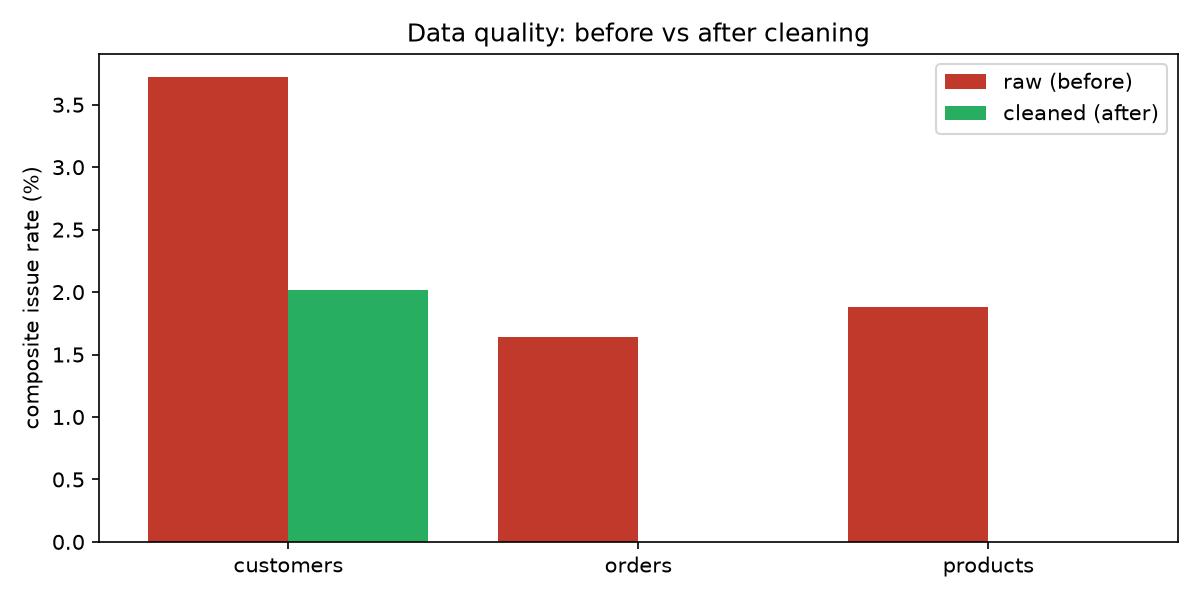

In [8]:
from data_quality import profile_clean

dq_clean = profile_clean(stg)
before = issue_score(dq_raw)
after = issue_score(dq_clean)
print("before:", before)
print("after :", after)

x = np.arange(len(before))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, list(before.values()), 0.4, label="raw (before)", color="#c0392b")
ax.bar(x + 0.2, list(after.values()), 0.4, label="cleaned (after)", color="#27ae60")
ax.set_xticks(x, list(before.keys()))
ax.set_ylabel("composite issue rate (%)")
ax.set_title("Data quality: before vs after cleaning")
ax.legend()
fig.tight_layout()
fig.savefig(REPO / "images" / "dq_before_after.png", dpi=150)
display(Image(str(REPO / "images" / "dq_before_after.png")))

## 8. Sample mart queries (SQL against the warehouse)

In [9]:
q_tier = (
    "SELECT c.loyalty_tier, "
    "COUNT(DISTINCT f.order_id) AS orders, "
    "ROUND(SUM(f.line_total), 2) AS revenue, "
    "ROUND(SUM(f.line_margin), 2) AS margin, "
    "ROUND(AVG(f.line_total), 2) AS avg_order_value "
    "FROM fact_orders f "
    "JOIN dim_customer c ON f.customer_sk = c.customer_sk "
    "GROUP BY 1 ORDER BY revenue DESC"
)
display(pd.read_sql(q_tier, conn))

q_month = (
    "SELECT d.year, d.month, d.month_name, "
    "ROUND(SUM(f.line_total), 2) AS revenue "
    "FROM fact_orders f "
    "JOIN dim_date d ON f.date_sk = d.date_sk "
    "GROUP BY 1, 2, 3 ORDER BY 1, 2"
)
monthly = pd.read_sql(q_month, conn)
display(monthly.head(6))
print("...")
display(monthly.tail(3))

q_cat = (
    "SELECT p.category, p.subcategory, COUNT(*) AS units_sold, "
    "ROUND(SUM(f.line_total), 2) AS revenue "
    "FROM fact_orders f "
    "JOIN dim_product p ON f.product_sk = p.product_sk "
    "GROUP BY 1, 2 ORDER BY revenue DESC LIMIT 8"
)
display(pd.read_sql(q_cat, conn))

,loyalty_tier,orders,revenue,margin,avg_order_value
0,Silver,594,331548.76,252158.49,558.16
1,Bronze,574,291154.37,220251.08,507.24
2,Gold,496,275794.79,218079.91,556.04
3,Platinum,526,268159.32,204109.58,509.81
4,Unknown,91,47395.07,36838.42,520.82


,year,month,month_name,revenue
0,2024,1,January,57151.64
1,2024,2,February,47001.38
2,2024,3,March,60011.04
3,2024,4,April,76206.33
4,2024,5,May,50311.18
5,2024,6,June,43861.35


...


,year,month,month_name,revenue
18,2025,7,July,67329.16
19,2025,8,August,87434.64
20,2025,9,September,83086.77


,category,subcategory,units_sold,revenue
0,Electronics,Accessories,304,156362.51
1,Clothing,Tops,230,133059.26
2,Home & Kitchen,Appliances,157,87251.93
3,Electronics,Audio,149,81190.79
4,Sports,Outdoor,128,71037.71
5,Clothing,Bottoms,143,70236.31
6,Sports,Fitness,127,68621.52
7,Home & Kitchen,Decor,136,66037.05


## 9. EDA — monthly revenue trend

In [10]:
monthly["period"] = pd.to_datetime(monthly[["year", "month"]].assign(day=1))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly["period"], monthly["revenue"], marker="o", color="#2c3e50")
ax.set_title("Monthly revenue (fact_orders x dim_date)")
ax.set_ylabel("revenue ($)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
peak = monthly.loc[monthly["revenue"].idxmax()]
print(f"Total revenue: ${monthly['revenue'].sum():,.2f} | "
      f"peak month: {peak['month_name']} {peak['year']}")

Total revenue: $1,214,052.31 | peak month: August 2025


## 10. Pipeline architecture

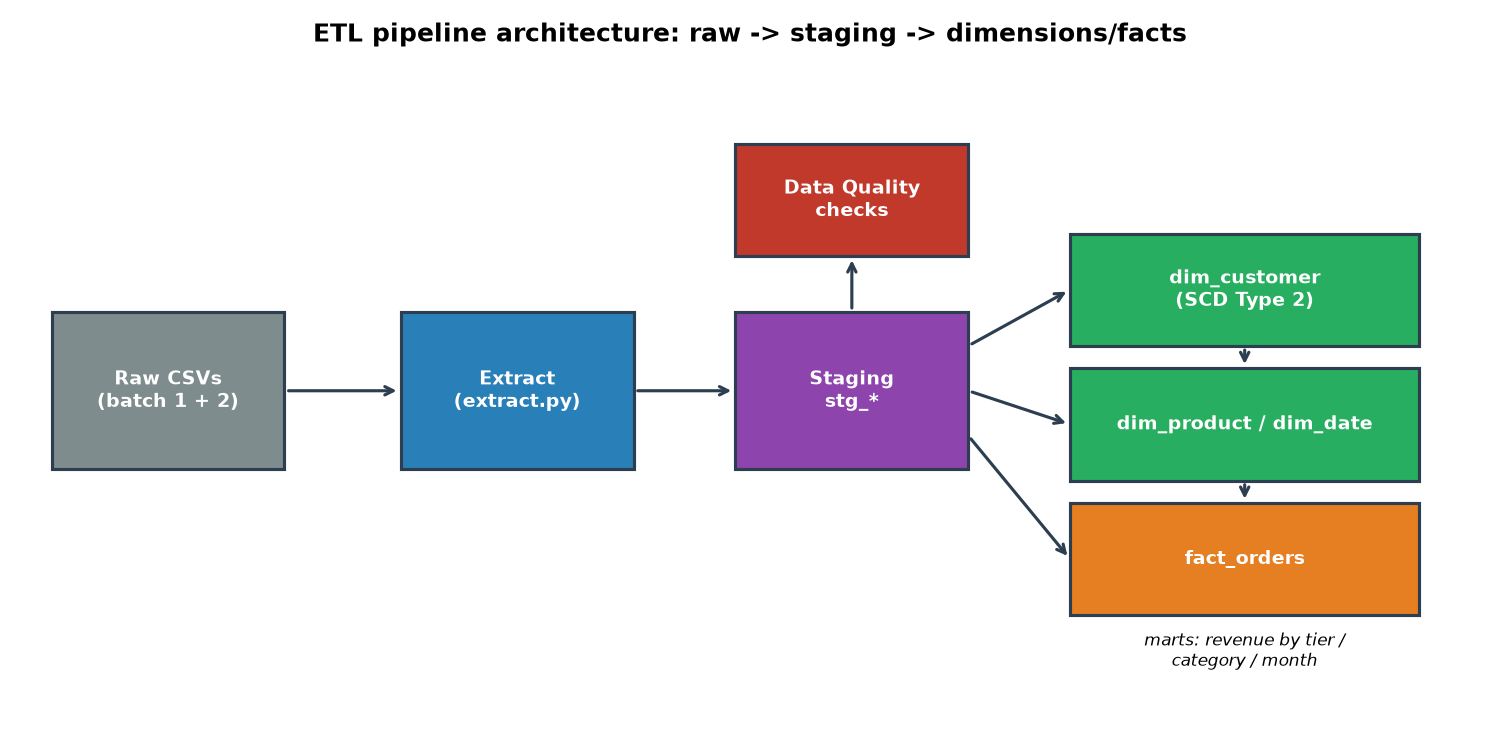

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")

def box(x, y, w, h, text, fc):
    ax.add_patch(plt.Rectangle((x, y), w, h, fc=fc, ec="#2c3e50", lw=1.5))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=9,
            weight="bold", color="white")

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=1.5, color="#2c3e50"))

box(0.2, 2.3, 1.6, 1.4, "Raw CSVs\n(batch 1 + 2)", "#7f8c8d")
box(2.6, 2.3, 1.6, 1.4, "Extract\n(extract.py)", "#2980b9")
box(4.9, 2.3, 1.6, 1.4, "Staging\nstg_*", "#8e44ad")
box(4.9, 4.2, 1.6, 1.0, "Data Quality\nchecks", "#c0392b")
box(7.2, 3.4, 2.4, 1.0, "dim_customer\n(SCD Type 2)", "#27ae60")
box(7.2, 2.2, 2.4, 1.0, "dim_product / dim_date", "#27ae60")
box(7.2, 1.0, 2.4, 1.0, "fact_orders", "#e67e22")
arrow(1.8, 3.0, 2.6, 3.0); arrow(4.2, 3.0, 4.9, 3.0)
arrow(5.7, 3.7, 5.7, 4.2)
arrow(6.5, 3.4, 7.2, 3.9); arrow(6.5, 3.0, 7.2, 2.7); arrow(6.5, 2.6, 7.2, 1.5)
arrow(8.4, 3.4, 8.4, 3.2); arrow(8.4, 2.2, 8.4, 2.0)
ax.text(8.4, 0.55, "marts: revenue by tier /\ncategory / month", ha="center",
        fontsize=8, style="italic")
ax.set_title("ETL pipeline architecture: raw -> staging -> dimensions/facts",
             fontsize=12, weight="bold")
fig.tight_layout()
fig.savefig(REPO / "images" / "architecture.png", dpi=150)
display(Image(str(REPO / "images" / "architecture.png")))
conn.close()

## Key insights (from the actual warehouse)

- Cleaning removed **7.4% duplicate customers** and **3.9% duplicate orders**,
  fixed **14.6% invalid emails**, and excluded **120 orphan order rows** with
  broken foreign keys — the fact table is fully referentially clean.
- SCD Type 2 preserved history for **30 customers** whose tier/city changed
  between batches: 530 current rows serve BI, 30 history rows serve
  point-in-time analysis.
- The marts answer KPI questions directly in SQL: revenue / margin / AOV by
  loyalty tier, category and subcategory performance, and monthly revenue trend.

**Resume-ready:** Built an end-to-end ETL pipeline in Python loading messy
synthetic retail data into a SQLite warehouse with SCD Type 2 dimensions,
data-quality checks, and dbt-style staging/mart layers.